# Spatial Reorganization of Gene Programs During Planarian Regeneration

Exploratory analysis of six Visium regeneration time points using Scanpy and Squidpy. See [README.md](README.md) for data sources, setup, methods, and limitations. Saved results are retained from the original STAT 530 project.

## STAT 530 Project

Continue your study of how planarians regenerate, using data from the planarian paper we have been studying in class ([Cui et al., 2023](https://www.nature.com/articles/s41467-023-39016-0)).

Answer four specific biological questions. Your questions should not contain any analyses that we performed in class. Answer the questions in this Jupyter notebook, interpret the results, export it to HTML, submit it to Canvas, and include all of your code. Any analysis with code that runs with errors will get 0 points.

You will be graded on:

1. Sophistication of scientific reasoning: scientific questions follow logically from each other, ask more than just the simplest questions
2. Sophistication of analyses: analyses appropriately answer the questions posed, interpretation is correct and ties into follow-up scientific questions
3. Effort: really try to dig into the science and the analysis 

### Question 1

#### 1a. (2 points)

State a specific biological question and explain why you are asking this question.

1a. Which genes show the strongest spatial organization at each regeneration time point?

Planarian regeneration should not affect all genes randomly across the tissue. Some genes should show spatially structured expression because regeneration happens in organized body regions. So, this question is to identify which genes have the strongest spatial patterns at each time point.

#### 1b. (2 points)

Analyze the data to answer your question. Include at least one visualization.

In [1]:
import os
os.environ["MPLCONFIGDIR"] = "/tmp/matplotlib"

import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc
import squidpy as sq

warnings.filterwarnings("ignore")
sc.settings.verbosity = 1

data_dir = Path(os.environ.get("PLANARIAN_DATA_DIR", "data")).expanduser()
visium_dir = data_dir / "Scanpy_Visium"
ref_path = data_dir / "singlecell_h5ad" / "adata_scRNA_Annotated.h5ad"
timepoint_files = {
    "0h": "Visium_0hpa.h5ad",
    "6h": "Visium_6hpa.h5ad",
    "12h": "Visium_12hpa.h5ad",
    "1d": "Visium_1dpa.h5ad",
    "3d": "Visium_3dpa.h5ad",
    "7d": "Visium_7dpa.h5ad",
}


required_files = [visium_dir / name for name in timepoint_files.values()] + [ref_path]
missing_files = [str(path) for path in required_files if not path.is_file()]
if missing_files:
    raise FileNotFoundError(
        "Required data files are missing. See README.md for downloads and set "
        "PLANARIAN_DATA_DIR if needed:\n" + "\n".join(missing_files)
    )

def section_name_for(timepoint):
    if timepoint == "1d":
        return "cut24h_A1"
    return f"cut{timepoint}_A1"


def load_and_preprocess_visium(timepoint, filename):
    adata = sc.read_h5ad(visium_dir / filename)
    adata.var_names_make_unique()

    section_name = section_name_for(timepoint)
    z_values = adata.obs["Z_3D"].astype(float)
    adata = adata[
        (adata.obs["library_id"] == section_name)
        & (z_values == 1.0)
    ].copy()

    if "in_tissue" in adata.obs.columns:
        adata = adata[adata.obs["in_tissue"] == 1].copy()

    adata.uns["spatial"] = {section_name: adata.uns["spatial"][section_name]}
    adata.layers["counts"] = adata.X.copy()

    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
    sc.pp.highly_variable_genes(adata, n_top_genes=2000)
    sc.tl.pca(adata, n_comps=20)
    sc.pp.neighbors(adata)
    sq.gr.spatial_neighbors(adata)

    return adata


visiums = {}
for timepoint, filename in timepoint_files.items():
    visiums[timepoint] = load_and_preprocess_visium(timepoint, filename)

preprocessing_summary = pd.DataFrame({
    "timepoint": list(visiums.keys()),
    "section": [section_name_for(timepoint) for timepoint in visiums],
    "spots": [adata.n_obs for adata in visiums.values()],
    "genes": [adata.n_vars for adata in visiums.values()],
    "highly_variable_genes": [int(adata.var["highly_variable"].sum()) for adata in visiums.values()],
})
preprocessing_summary


INFO     Creating graph using `grid` coordinates and `None` transform and `1` libraries.                           
INFO     Creating graph using `grid` coordinates and `None` transform and `1` libraries.                           
INFO     Creating graph using `grid` coordinates and `None` transform and `1` libraries.                           
INFO     Creating graph using `grid` coordinates and `None` transform and `1` libraries.                           
INFO     Creating graph using `grid` coordinates and `None` transform and `1` libraries.                           
INFO     Creating graph using `grid` coordinates and `None` transform and `1` libraries.                           


,timepoint,section,spots,genes,highly_variable_genes
0,0h,cut0h_A1,977,27664,2000
1,6h,cut6h_A1,870,27664,2000
2,12h,cut12h_A1,1115,27664,2000
3,1d,cut24h_A1,901,27664,2000
4,3d,cut3d_A1,1231,27664,2000
5,7d,cut7d_A1,1176,27664,2000


In [2]:
moran_results = {}
q1_top_records = []

for timepoint, adata in visiums.items():
    hvg_genes = adata.var_names[adata.var["highly_variable"]].tolist()

    sq.gr.spatial_autocorr(
        adata,
        mode="moran",
        genes=hvg_genes,
        n_perms=None,
        n_jobs=1,
        show_progress_bar=False,
    )

    moran_df = adata.uns["moranI"].copy()
    moran_df["gene"] = moran_df.index
    moran_df["timepoint"] = timepoint
    moran_results[timepoint] = moran_df

    q1_top_records.append(moran_df.head(10))

q1_top_genes = pd.concat(q1_top_records, ignore_index=True)
q1_top_genes[["timepoint", "gene", "I", "pval_norm", "pval_norm_fdr_bh"]]


,timepoint,gene,I,pval_norm,pval_norm_fdr_bh
0,0h,SMED30033452,0.865099,0.0,0.0
1,0h,SMED30005126,0.859842,0.0,0.0
2,0h,SMED30004645,0.849743,0.0,0.0
3,0h,SMED30031322,0.846327,0.0,0.0
4,0h,SMED30011206,0.845053,0.0,0.0
5,0h,SMED30008672,0.844813,0.0,0.0
6,0h,SMED30032339,0.843418,0.0,0.0
7,0h,SMED30022805,0.842887,0.0,0.0
8,0h,SMED30021979,0.842841,0.0,0.0
9,0h,SMED30029969,0.840118,0.0,0.0


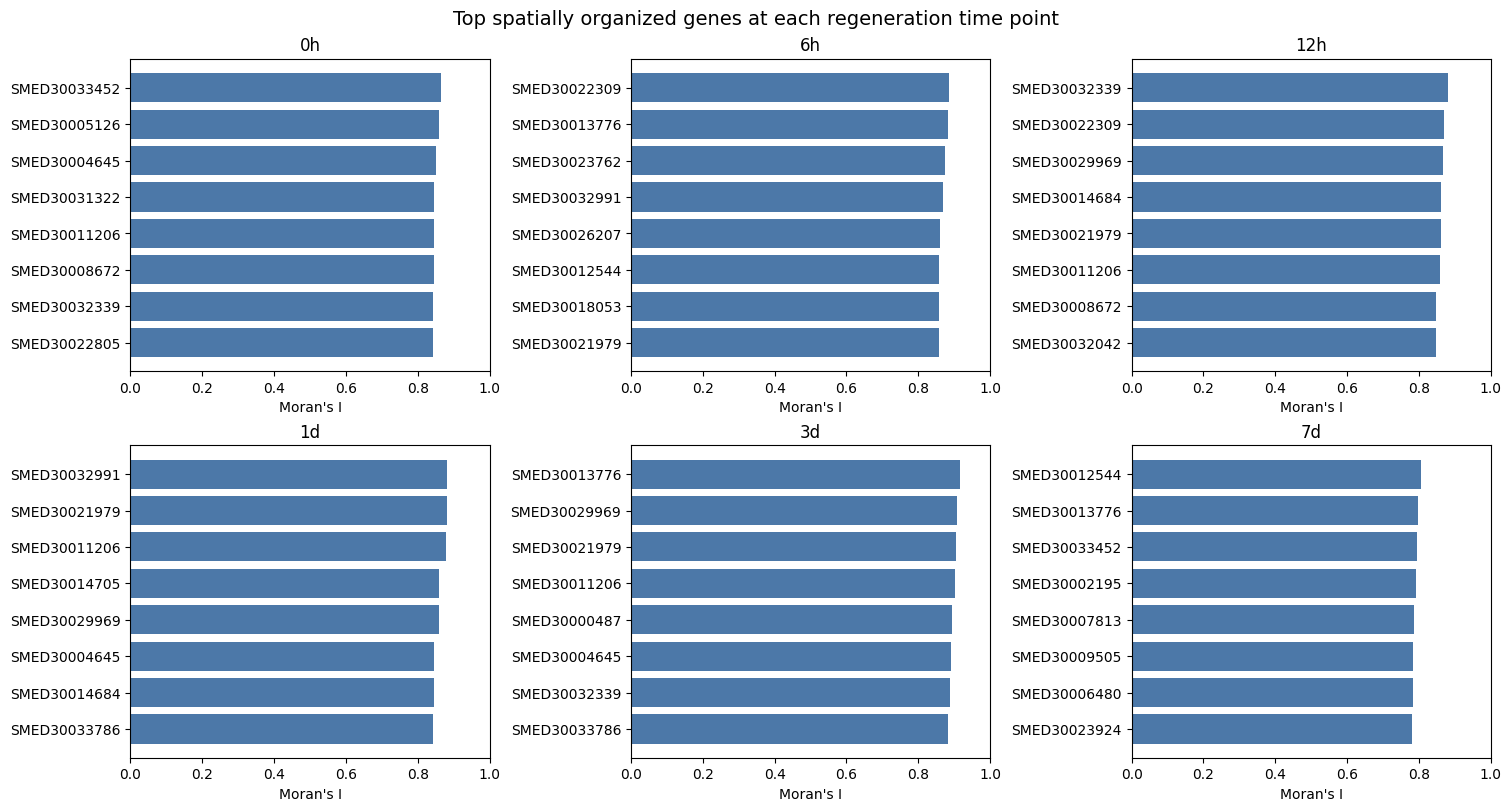

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
axes = axes.flatten()

for ax, (timepoint, moran_df) in zip(axes, moran_results.items()):
    top = moran_df.head(8).sort_values("I")
    ax.barh(top["gene"], top["I"], color="#4C78A8")
    ax.set_title(timepoint)
    ax.set_xlabel("Moran's I")
    ax.set_xlim(0, 1)

fig.suptitle("Top spatially organized genes at each regeneration time point", fontsize=14)
plt.show()


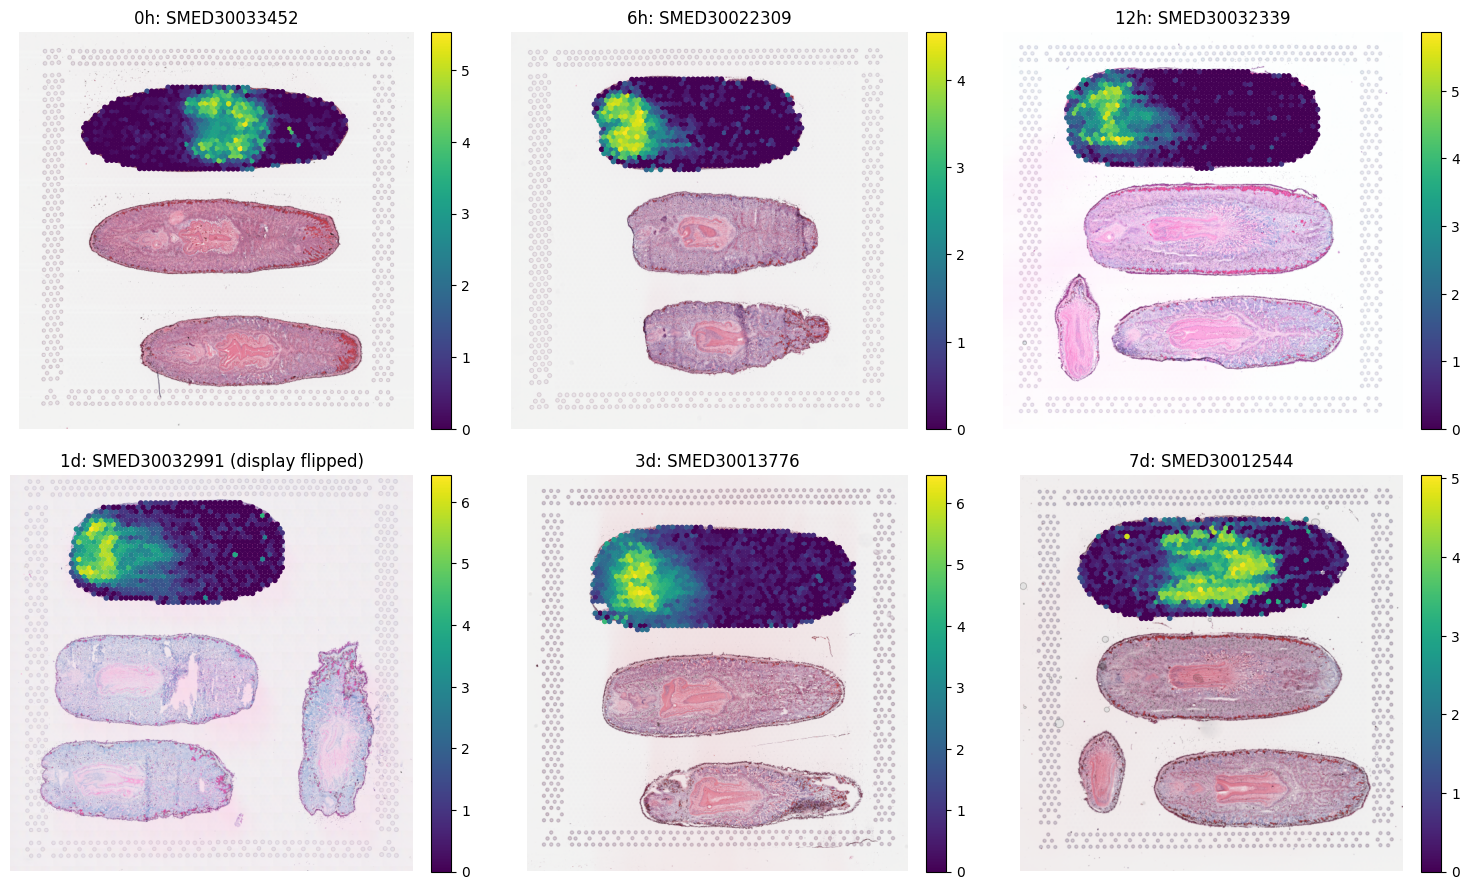

In [6]:
flipped_timepoints = {"1d"}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for ax, (timepoint, adata) in zip(axes, visiums.items()):
    top_gene = moran_results[timepoint].iloc[0]["gene"]
    key = list(adata.uns["spatial"].keys())[0]
    spatial_info = adata.uns["spatial"][key]
    scale = spatial_info["scalefactors"]["tissue_lowres_scalef"]
    img = spatial_info["images"]["lowres"]
    coords = adata.obsm["spatial"] * scale
    expression = adata[:, top_gene].X

    if hasattr(expression, "toarray"):
        expression = expression.toarray()
    expression = expression.ravel()

    if timepoint in flipped_timepoints:
        img = img[:, ::-1]
        coords = coords.copy()
        coords[:, 0] = img.shape[1] - coords[:, 0]

    ax.imshow(img)
    points = ax.scatter(
        coords[:, 0],
        coords[:, 1],
        c=expression,
        cmap="viridis",
        s=16,
        linewidths=0,
    )
    flip_label = " (display flipped)" if timepoint in flipped_timepoints else ""
    ax.set_title(f"{timepoint}: {top_gene}{flip_label}")
    ax.set_xlim(0, img.shape[1])
    ax.set_ylim(img.shape[0], 0)
    ax.axis("off")
    fig.colorbar(points, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()


The strongest spatially organized genes have high Moran's I values at every time point, meaning nearby spots tend to have similar expression for these genes. For visual comparison across time points, the 1d section is shown with a horizontal display flip based on the section-orientation check from the previous analysis; this does not change the Moran's I calculation. Some top-ranked genes recur across multiple early and middle regeneration time points, but the exact top genes also change across time, especially by 7d. This suggests that regeneration has persistent spatial structure while the genes contributing most strongly to that structure may change over the time course.


### Question 2

#### 2a. (2 points)

State a specific biological question and explain why the answer to your previous question led you to ask this new question.

2a. How do regeneration-associated gene programs change across space and time?

Q1 showed that many individual genes have strong spatial organization, but single genes can be noisy and difficult to interpret biologically. This leads to a broader question: whether groups of genes representing wound response, neoblast/stem-cell state, and differentiated tissue identity show coordinated spatial and temporal patterns during regeneration.


#### 2b. (2 points)

Analyze the data to answer your question. Include at least one visualization.

In [ ]:
import numpy as np

ref = sc.read_h5ad(ref_path).copy()
ref.var_names_make_unique()

sc.pp.normalize_total(ref, target_sum=1e4)
sc.pp.log1p(ref)

# Neoblast and differentiated-tissue programs come from broad annotated cell classes.
sc.tl.rank_genes_groups(ref, groupby="BigCellType", method="wilcoxon")


def top_markers(adata, group, n=30):
    markers = sc.get.rank_genes_groups_df(adata, group=group)
    markers = markers.sort_values("scores", ascending=False)
    return markers["names"].dropna().astype(str).head(n).tolist()


neoblast_genes = top_markers(ref, "Neoblast", n=40)
epidermal_genes = top_markers(ref, "Epidermal", n=20)
muscle_genes = top_markers(ref, "Muscle", n=20)
neural_genes = top_markers(ref, "Neuronal", n=20)

differentiation_genes = list(dict.fromkeys(
    epidermal_genes + muscle_genes + neural_genes
))

# Early wound-response markers are genes enriched in early post-amputation single cells compared with the uninjured 0d reference.
ref_wound = ref[ref.obs["TimePoint"].isin(["cut0d", "cut6h", "cut12h", "cut24h"])].copy()
ref_wound.obs["wound_group"] = np.where(
    ref_wound.obs["TimePoint"].isin(["cut6h", "cut12h", "cut24h"]),
    "early_wound",
    "homeostatic",
)
sc.tl.rank_genes_groups(
    ref_wound,
    groupby="wound_group",
    groups=["early_wound"],
    reference="homeostatic",
    method="wilcoxon",
)
wound_response_genes = top_markers(ref_wound, "early_wound", n=40)

program_gene_sets = {
    "wound_response": wound_response_genes,
    "neoblast": neoblast_genes,
    "differentiation": differentiation_genes,
}

gene_set_summary = []
for program, genes in program_gene_sets.items():
    genes_in_visium = [gene for gene in genes if gene in next(iter(visiums.values())).var_names]
    gene_set_summary.append({
        "program": program,
        "genes_selected": len(genes),
        "genes_in_visium": len(genes_in_visium),
        "example_genes": ", ".join(genes_in_visium[:8]),
    })

pd.DataFrame(gene_set_summary)


,program,genes_selected,genes_in_visium,example_genes
0,wound_response,40,40,"SMED30027385, SMED30010488, SMED30031105, SMED..."
1,neoblast,40,40,"SMED30007406, SMED30031463, SMED30019803, SMED..."
2,differentiation,60,60,"SMED30022344, SMED30009457, SMED30026364, SMED..."


In [8]:
program_score_names = {
    "wound_response": "wound_response_score",
    "neoblast": "neoblast_score",
    "differentiation": "differentiation_score",
}

for timepoint, adata in visiums.items():
    for program, genes in program_gene_sets.items():
        genes_in_visium = [gene for gene in genes if gene in adata.var_names]
        if len(genes_in_visium) < 5:
            raise ValueError(f"Only {len(genes_in_visium)} {program} genes found in {timepoint} Visium data")
        sc.tl.score_genes(
            adata,
            gene_list=genes_in_visium,
            score_name=program_score_names[program],
        )

score_records = []
for timepoint, adata in visiums.items():
    for program, score_name in program_score_names.items():
        score_records.append({
            "timepoint": timepoint,
            "program": program,
            "mean_score": adata.obs[score_name].mean(),
            "median_score": adata.obs[score_name].median(),
        })

program_score_summary = pd.DataFrame(score_records)
program_score_summary["timepoint"] = pd.Categorical(
    program_score_summary["timepoint"],
    categories=list(timepoint_files.keys()),
    ordered=True,
)
program_score_summary.sort_values(["program", "timepoint"])


,timepoint,program,mean_score,median_score
2,0h,differentiation,0.502543,0.451823
5,6h,differentiation,0.536966,0.471176
8,12h,differentiation,0.686709,0.634076
11,1d,differentiation,0.463448,0.390640
14,3d,differentiation,0.533184,0.464173
17,7d,differentiation,0.559144,0.511703
1,0h,neoblast,0.452416,0.449470
4,6h,neoblast,0.533101,0.548384
7,12h,neoblast,0.548382,0.547741
10,1d,neoblast,0.591167,0.598683


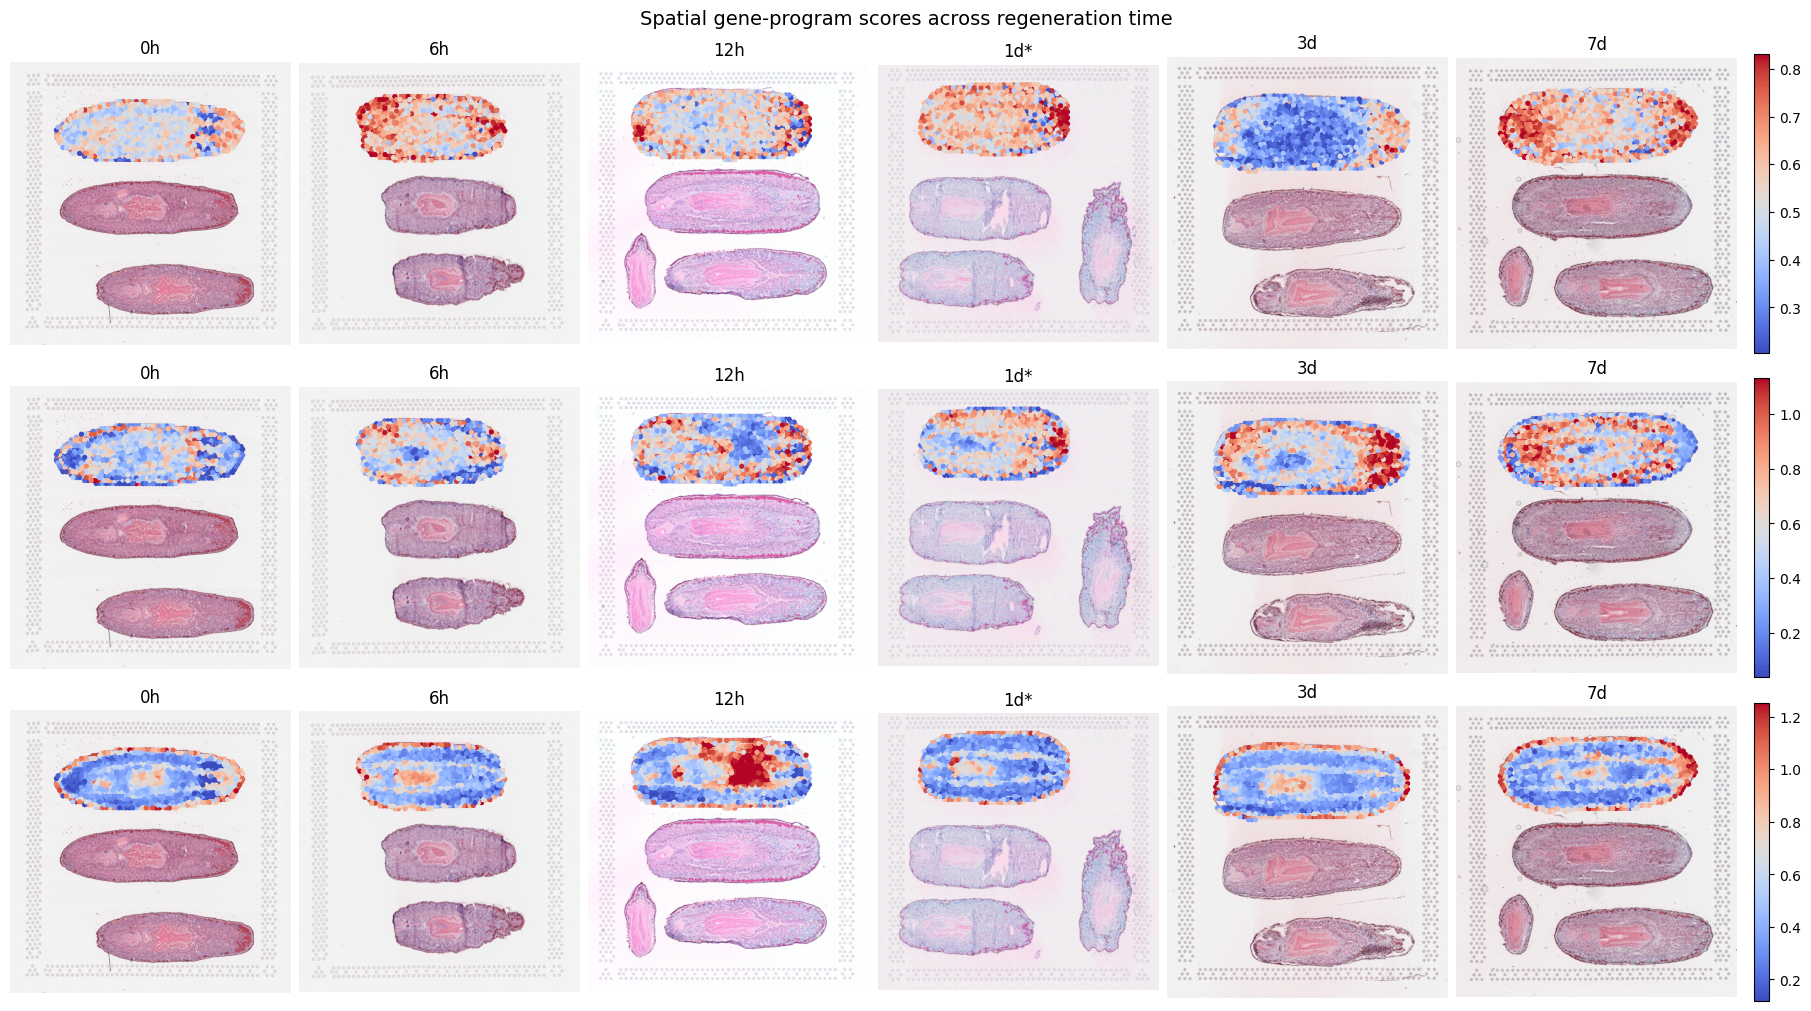

In [9]:
def spatial_plot_inputs(adata, timepoint):
    key = list(adata.uns["spatial"].keys())[0]
    spatial_info = adata.uns["spatial"][key]
    scale = spatial_info["scalefactors"]["tissue_lowres_scalef"]
    img = spatial_info["images"]["lowres"]
    coords = adata.obsm["spatial"] * scale

    if timepoint in flipped_timepoints:
        img = img[:, ::-1]
        coords = coords.copy()
        coords[:, 0] = img.shape[1] - coords[:, 0]

    return img, coords


score_limits = {}
for program, score_name in program_score_names.items():
    all_scores = np.concatenate([
        adata.obs[score_name].to_numpy()
        for adata in visiums.values()
    ])
    score_limits[score_name] = (
        np.quantile(all_scores, 0.02),
        np.quantile(all_scores, 0.98),
    )

fig, axes = plt.subplots(
    len(program_score_names),
    len(visiums),
    figsize=(18, 10),
    constrained_layout=True,
)

for row, (program, score_name) in enumerate(program_score_names.items()):
    vmin, vmax = score_limits[score_name]
    for col, (timepoint, adata) in enumerate(visiums.items()):
        ax = axes[row, col]
        img, coords = spatial_plot_inputs(adata, timepoint)
        values = adata.obs[score_name].to_numpy()

        ax.imshow(img)
        points = ax.scatter(
            coords[:, 0],
            coords[:, 1],
            c=values,
            cmap="coolwarm",
            vmin=vmin,
            vmax=vmax,
            s=14,
            linewidths=0,
        )
        flip_label = "*" if timepoint in flipped_timepoints else ""
        ax.set_title(f"{timepoint}{flip_label}")
        ax.set_xlim(0, img.shape[1])
        ax.set_ylim(img.shape[0], 0)
        ax.axis("off")

        if col == 0:
            ax.set_ylabel(program.replace("_", " "), fontsize=11)

    fig.colorbar(points, ax=axes[row, :], fraction=0.018, pad=0.01)

fig.suptitle("Spatial gene-program scores across regeneration time", fontsize=14)
plt.show()


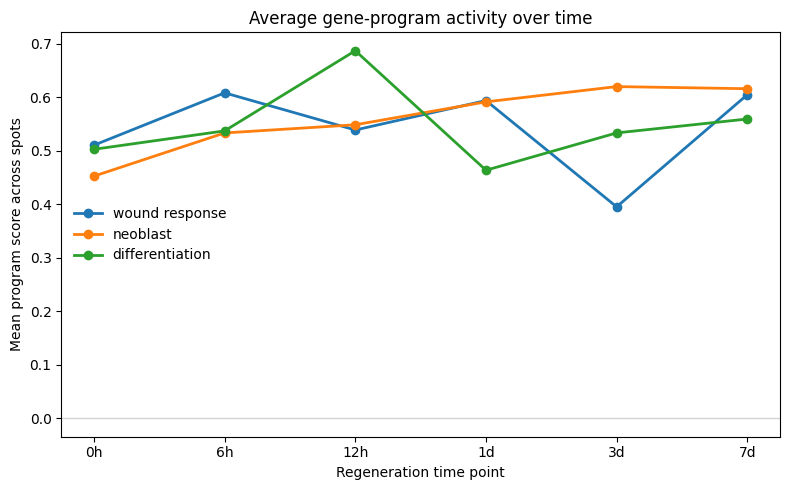

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))

for program in program_score_names:
    subset = program_score_summary[program_score_summary["program"] == program].sort_values("timepoint")
    ax.plot(
        subset["timepoint"].astype(str),
        subset["mean_score"],
        marker="o",
        linewidth=2,
        label=program.replace("_", " "),
    )

ax.axhline(0, color="lightgray", linewidth=1)
ax.set_xlabel("Regeneration time point")
ax.set_ylabel("Mean program score across spots")
ax.set_title("Average gene-program activity over time")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


The program-score analysis extends Q1 from individual spatial genes to broader biological programs. I selected three programs because they represent major biological components of regeneration: wound-response genes mark the early transcriptional response to amputation, neoblast genes mark the stem-cell population required for regeneration, and differentiation genes mark mature tissue identities such as epidermal, muscle, and neuronal states. Scoring these programs makes the analysis less dependent on any single spatially variable gene.

The results show that all three programs have spatially patterned activity within the tissue sections. The neoblast program shows the clearest temporal trend, increasing from 0h through the later regeneration time points and remaining high at 3d and 7d. The wound-response program is high at 6h and 1d, but it does not simply decrease over time because it is lower at 3d and higher again at 7d. The differentiation program is also non-monotonic, with a strong increase at 12h followed by a decrease at 1d. These patterns suggest that regeneration-associated programs are reorganized across both space and time rather than turning on and off in a simple linear sequence.


### Question 3

#### 3a. (2 points)

State a specific biological question and explain why the answer to your previous question led you to ask this new question.

3a. Do regeneration-related programs become more spatially clustered over time?

Q2 showed that wound-response, neoblast, and differentiation programs have spatially patterned scores, but score maps alone do not quantify whether high-scoring spots are organized into local domains. So, this leads to our next question: whether spots with high regeneration-program activity are more likely to neighbor spots from the same program group, and whether that local spatial organization changes across regeneration time.


#### 3b. (2 points)

Analyze the data to answer your question. Include at least one visualization.

In [16]:
program_group_labels = {
    "wound_response": "high_wound_response",
    "neoblast": "high_neoblast",
    "differentiation": "high_differentiation",
}
program_group_order = [
    "high_wound_response",
    "high_neoblast",
    "high_differentiation",
    "other",
]

program_group_records = []

for timepoint, adata in visiums.items():
    score_df = pd.DataFrame({
        program: adata.obs[score_name].to_numpy()
        for program, score_name in program_score_names.items()
    }, index=adata.obs_names)

    high_flags = pd.DataFrame(False, index=score_df.index, columns=score_df.columns)
    for program in score_df.columns:
        cutoff = score_df[program].quantile(0.75)
        high_flags[program] = score_df[program] >= cutoff
        adata.obs[f"high_{program}"] = high_flags[program].to_numpy()

    z_scores = (score_df - score_df.mean(axis=0)) / score_df.std(axis=0)
    groups = []
    for spot in score_df.index:
        high_programs = high_flags.columns[high_flags.loc[spot]].tolist()
        if not high_programs:
            groups.append("other")
        else:
            dominant_program = z_scores.loc[spot, high_programs].idxmax()
            groups.append(program_group_labels[dominant_program])

    adata.obs["program_group"] = pd.Categorical(
        groups,
        categories=program_group_order,
        ordered=True,
    )

    group_counts = adata.obs["program_group"].value_counts().reindex(program_group_order, fill_value=0)
    for group, n_spots in group_counts.items():
        program_group_records.append({
            "timepoint": timepoint,
            "program_group": group,
            "n_spots": int(n_spots),
            "fraction_spots": n_spots / adata.n_obs,
        })

program_group_summary = pd.DataFrame(program_group_records)
program_group_summary["timepoint"] = pd.Categorical(
    program_group_summary["timepoint"],
    categories=list(timepoint_files.keys()),
    ordered=True,
)
program_group_summary.sort_values(["timepoint", "program_group"])


,timepoint,program_group,n_spots,fraction_spots
2,0h,high_differentiation,181,0.185261
1,0h,high_neoblast,206,0.210850
0,0h,high_wound_response,114,0.116684
3,0h,other,476,0.487206
6,6h,high_differentiation,173,0.198851
5,6h,high_neoblast,156,0.179310
4,6h,high_wound_response,129,0.148276
7,6h,other,412,0.473563
10,12h,high_differentiation,267,0.239462
9,12h,high_neoblast,227,0.203587


In [17]:
nhood_records = []

for timepoint, adata in visiums.items():
    sq.gr.nhood_enrichment(
        adata,
        cluster_key="program_group",
        n_perms=100,
        n_jobs=1,
        seed=0,
        show_progress_bar=False,
    )

    enrichment = adata.uns["program_group_nhood_enrichment"]
    zscores = pd.DataFrame(
        enrichment["zscore"],
        index=adata.obs["program_group"].cat.categories,
        columns=adata.obs["program_group"].cat.categories,
    )

    conn = adata.obsp["spatial_connectivities"].tocsr()
    upper = conn.copy()
    upper = upper.multiply(np.triu(np.ones(upper.shape), k=1))
    row_idx, col_idx = upper.nonzero()
    groups = adata.obs["program_group"].astype(str).to_numpy()

    for group in program_group_order:
        group_edges = (groups[row_idx] == group) | (groups[col_idx] == group)
        if group_edges.sum() == 0:
            same_group_fraction = np.nan
        else:
            same_group_edges = (groups[row_idx] == group) & (groups[col_idx] == group)
            same_group_fraction = same_group_edges.sum() / group_edges.sum()

        nhood_records.append({
            "timepoint": timepoint,
            "program_group": group,
            "same_group_neighbor_fraction": same_group_fraction,
            "self_enrichment_zscore": zscores.loc[group, group],
        })

nhood_summary = pd.DataFrame(nhood_records)
nhood_summary["timepoint"] = pd.Categorical(
    nhood_summary["timepoint"],
    categories=list(timepoint_files.keys()),
    ordered=True,
)
nhood_summary.sort_values(["program_group", "timepoint"])


,timepoint,program_group,same_group_neighbor_fraction,self_enrichment_zscore
2,0h,high_differentiation,0.333333,15.781708
6,6h,high_differentiation,0.362253,16.009657
10,12h,high_differentiation,0.555785,31.479346
14,1d,high_differentiation,0.343046,14.321133
18,3d,high_differentiation,0.406889,20.902551
22,7d,high_differentiation,0.378755,20.517821
1,0h,high_neoblast,0.227874,10.205516
5,6h,high_neoblast,0.191350,9.543742
9,12h,high_neoblast,0.261236,16.749806
13,1d,high_neoblast,0.204420,8.344675


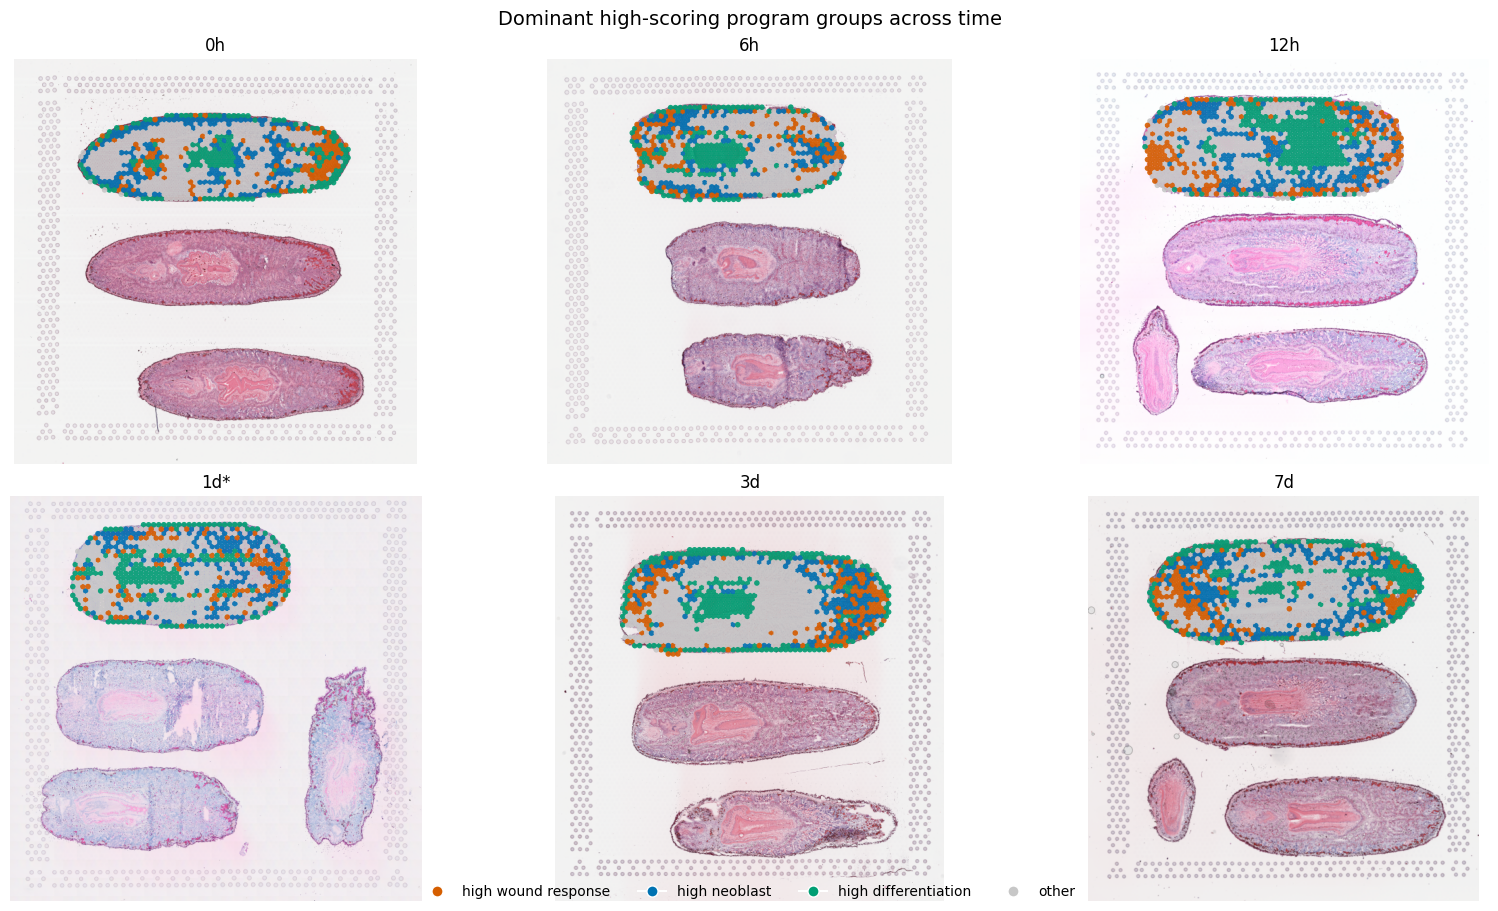

In [18]:
group_colors = {
    "high_wound_response": "#D55E00",
    "high_neoblast": "#0072B2",
    "high_differentiation": "#009E73",
    "other": "#C7C7C7",
}

fig, axes = plt.subplots(2, 3, figsize=(16, 9), constrained_layout=True)
axes = axes.flatten()

for ax, (timepoint, adata) in zip(axes, visiums.items()):
    img, coords = spatial_plot_inputs(adata, timepoint)
    groups = adata.obs["program_group"].astype(str)
    colors = groups.map(group_colors).to_numpy()

    ax.imshow(img)
    ax.scatter(coords[:, 0], coords[:, 1], c=colors, s=16, linewidths=0, alpha=0.9)
    flip_label = "*" if timepoint in flipped_timepoints else ""
    ax.set_title(f"{timepoint}{flip_label}")
    ax.set_xlim(0, img.shape[1])
    ax.set_ylim(img.shape[0], 0)
    ax.axis("off")

handles = [
    plt.Line2D([0], [0], marker="o", color="w", label=group.replace("_", " "),
               markerfacecolor=color, markersize=8)
    for group, color in group_colors.items()
]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False)
fig.suptitle("Dominant high-scoring program groups across time", fontsize=14)
plt.show()


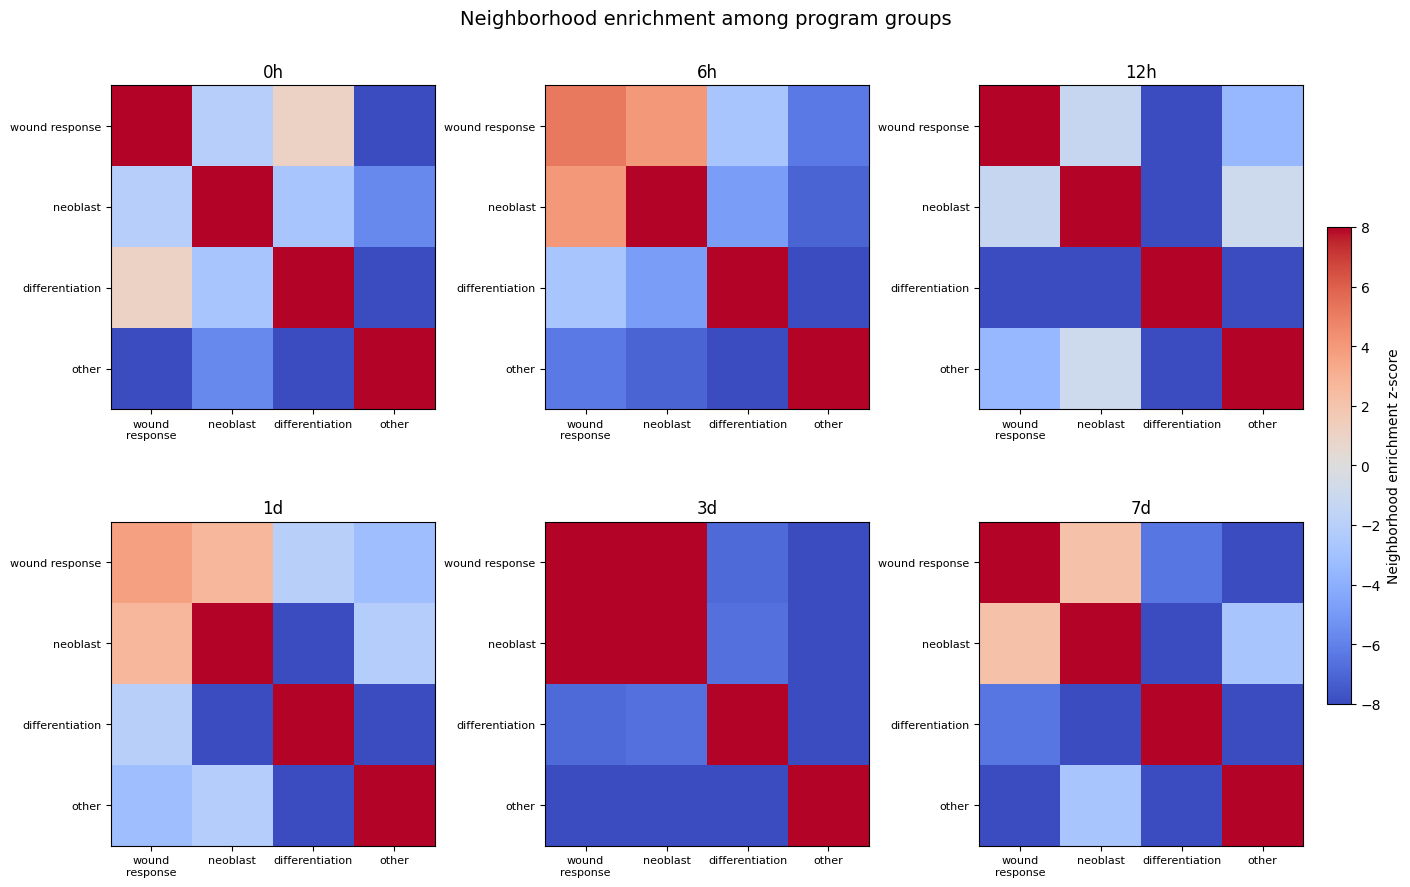

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(14, 9), constrained_layout=True)
axes = axes.flatten()

for ax, (timepoint, adata) in zip(axes, visiums.items()):
    enrichment = adata.uns["program_group_nhood_enrichment"]
    zscores = pd.DataFrame(
        enrichment["zscore"],
        index=adata.obs["program_group"].cat.categories,
        columns=adata.obs["program_group"].cat.categories,
    )
    zscores = zscores.loc[program_group_order, program_group_order]

    im = ax.imshow(zscores, cmap="coolwarm", vmin=-8, vmax=8)
    ax.set_title(timepoint)
    ax.set_xticks(range(len(program_group_order)))
    ax.set_yticks(range(len(program_group_order)))
    ax.set_xticklabels([g.replace("high_", "").replace("_", "\n") for g in program_group_order], fontsize=8)
    ax.set_yticklabels([g.replace("high_", "").replace("_", " ") for g in program_group_order], fontsize=8)
    ax.tick_params(axis="x", rotation=0)

fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02, label="Neighborhood enrichment z-score")
fig.suptitle("Neighborhood enrichment among program groups", fontsize=14)
plt.show()


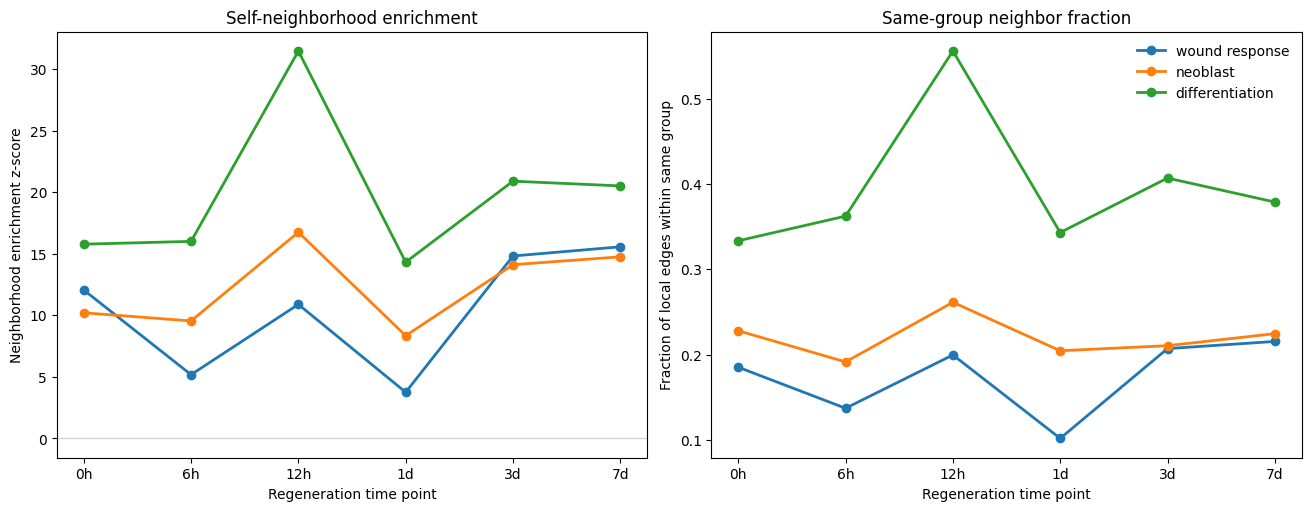

In [20]:
plot_groups = ["high_wound_response", "high_neoblast", "high_differentiation"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

for group in plot_groups:
    subset = nhood_summary[nhood_summary["program_group"] == group].sort_values("timepoint")
    label = group.replace("high_", "").replace("_", " ")
    axes[0].plot(
        subset["timepoint"].astype(str),
        subset["self_enrichment_zscore"],
        marker="o",
        linewidth=2,
        label=label,
    )
    axes[1].plot(
        subset["timepoint"].astype(str),
        subset["same_group_neighbor_fraction"],
        marker="o",
        linewidth=2,
        label=label,
    )

axes[0].axhline(0, color="lightgray", linewidth=1)
axes[0].set_title("Self-neighborhood enrichment")
axes[0].set_xlabel("Regeneration time point")
axes[0].set_ylabel("Neighborhood enrichment z-score")

axes[1].set_title("Same-group neighbor fraction")
axes[1].set_xlabel("Regeneration time point")
axes[1].set_ylabel("Fraction of local edges within same group")
axes[1].legend(frameon=False)

plt.show()


This analysis converts continuous program scores into spatial domains by labeling the top 25% of spots for each program and assigning each spot to its dominant high-scoring program group. The spatial maps show that high-scoring wound-response, neoblast, and differentiation spots form local regions rather than being evenly mixed across the tissue. The neighborhood enrichment analysis confirms this quantitatively: all three high-scoring program groups have positive self-enrichment z-scores across the regeneration time course, meaning spots from the same program group tend to be spatial neighbors more often than expected by chance.

The clustering pattern is not a simple monotonic increase over time. The high-differentiation group shows the strongest spatial clustering overall, with an especially strong peak at 12h. The high-neoblast group is also consistently clustered, with stronger enrichment at 12h, 3d, and 7d than at 1d. The high-wound-response group is clustered as well, but its enrichment is weaker at 6h and 1d and stronger at 3d and 7d. Together, these results suggest that regeneration-related programs are spatially organized throughout the time course, but their spatial domains are reorganized in a time-point-specific way rather than simply becoming progressively more clustered.


### Question 4

#### 4a. (2 points)

State a specific biological question and explain why the answer to your previous question led you to ask this new question.

4a. Which genes define the regenerative spatial niches identified across time?

Q3 showed that high-scoring wound-response, neoblast, and differentiation program groups form spatially clustered domains. So, the next question asks which genes characterize those domains. This can connect the spatial-domain analysis back to individual genes: after identifying regenerative niches, we can ask which marker genes are enriched in each niche at each regeneration time point.


#### 4b. (2 points)

Analyze the data to answer your question. Include at least one visualization.

In [21]:
q4_groups = ["high_wound_response", "high_neoblast", "high_differentiation"]
q4_marker_records = []

for timepoint, adata in visiums.items():
    adata.obs["program_group"] = adata.obs["program_group"].astype("category")

    for group in q4_groups:
        group_mask = adata.obs["program_group"] == group
        other_mask = adata.obs["program_group"] == "other"

        if group_mask.sum() < 10 or other_mask.sum() < 10:
            continue

        subset = adata[group_mask | other_mask].copy()
        subset.obs["de_group"] = np.where(
            subset.obs["program_group"].astype(str) == group,
            group,
            "other",
        )
        subset.obs["de_group"] = pd.Categorical(subset.obs["de_group"], categories=[group, "other"])

        sc.tl.rank_genes_groups(
            subset,
            groupby="de_group",
            groups=[group],
            reference="other",
            method="wilcoxon",
        )

        markers = sc.get.rank_genes_groups_df(subset, group=group).head(10).copy()
        markers["timepoint"] = timepoint
        markers["program_group"] = group
        markers["n_group_spots"] = int(group_mask.sum())
        markers["n_other_spots"] = int(other_mask.sum())
        q4_marker_records.append(markers)

q4_marker_table = pd.concat(q4_marker_records, ignore_index=True)
q4_marker_table = q4_marker_table.rename(columns={"names": "gene"})
q4_marker_table[[
    "timepoint",
    "program_group",
    "gene",
    "scores",
    "logfoldchanges",
    "pvals_adj",
    "n_group_spots",
    "n_other_spots",
]]


,timepoint,program_group,gene,scores,logfoldchanges,pvals_adj,n_group_spots,n_other_spots
0,0h,high_wound_response,SMED30005171,11.742261,1.159413,2.140906e-27,114,476
1,0h,high_wound_response,SMED30026225,11.635213,1.098925,3.774878e-27,114,476
2,0h,high_wound_response,SMED30019874,11.136369,1.195314,7.695507e-25,114,476
3,0h,high_wound_response,SMED30012075,11.008217,1.192513,2.412581e-24,114,476
4,0h,high_wound_response,SMED30033594,10.983442,1.599835,2.540044e-24,114,476
...,...,...,...,...,...,...,...,...
175,7d,high_differentiation,SMED30008655,16.214851,2.106499,1.825999e-55,253,526
176,7d,high_differentiation,SMED30004267,15.961205,3.317350,9.409421e-54,253,526
177,7d,high_differentiation,SMED30015362,15.943014,3.930733,1.101753e-53,253,526
178,7d,high_differentiation,SMED30021105,15.612865,1.180669,1.829009e-51,253,526


In [22]:
q4_top_marker_summary = (
    q4_marker_table
    .sort_values(["timepoint", "program_group", "scores"], ascending=[True, True, False])
    .groupby(["timepoint", "program_group"], observed=True)
    .head(3)
    [["timepoint", "program_group", "gene", "scores", "logfoldchanges", "pvals_adj"]]
)
q4_top_marker_summary


,timepoint,program_group,gene,scores,logfoldchanges,pvals_adj
20,0h,high_differentiation,SMED30001515,16.590544,2.730509,1.167956e-57
21,0h,high_differentiation,SMED30004485,16.588474,3.174804,1.167956e-57
22,0h,high_differentiation,SMED30026887,16.542927,2.332425,1.660396e-57
10,0h,high_neoblast,SMED30007406,19.101189,2.057916,6.827554e-77
11,0h,high_neoblast,SMED30019803,18.775463,1.856442,1.658420e-74
12,0h,high_neoblast,SMED30030234,18.550058,1.798053,7.511966e-73
0,0h,high_wound_response,SMED30005171,11.742261,1.159413,2.140906e-27
1,0h,high_wound_response,SMED30026225,11.635213,1.098925,3.774878e-27
2,0h,high_wound_response,SMED30019874,11.136369,1.195314,7.695507e-25
80,12h,high_differentiation,SMED30014876,19.995552,4.100326,1.665640e-84


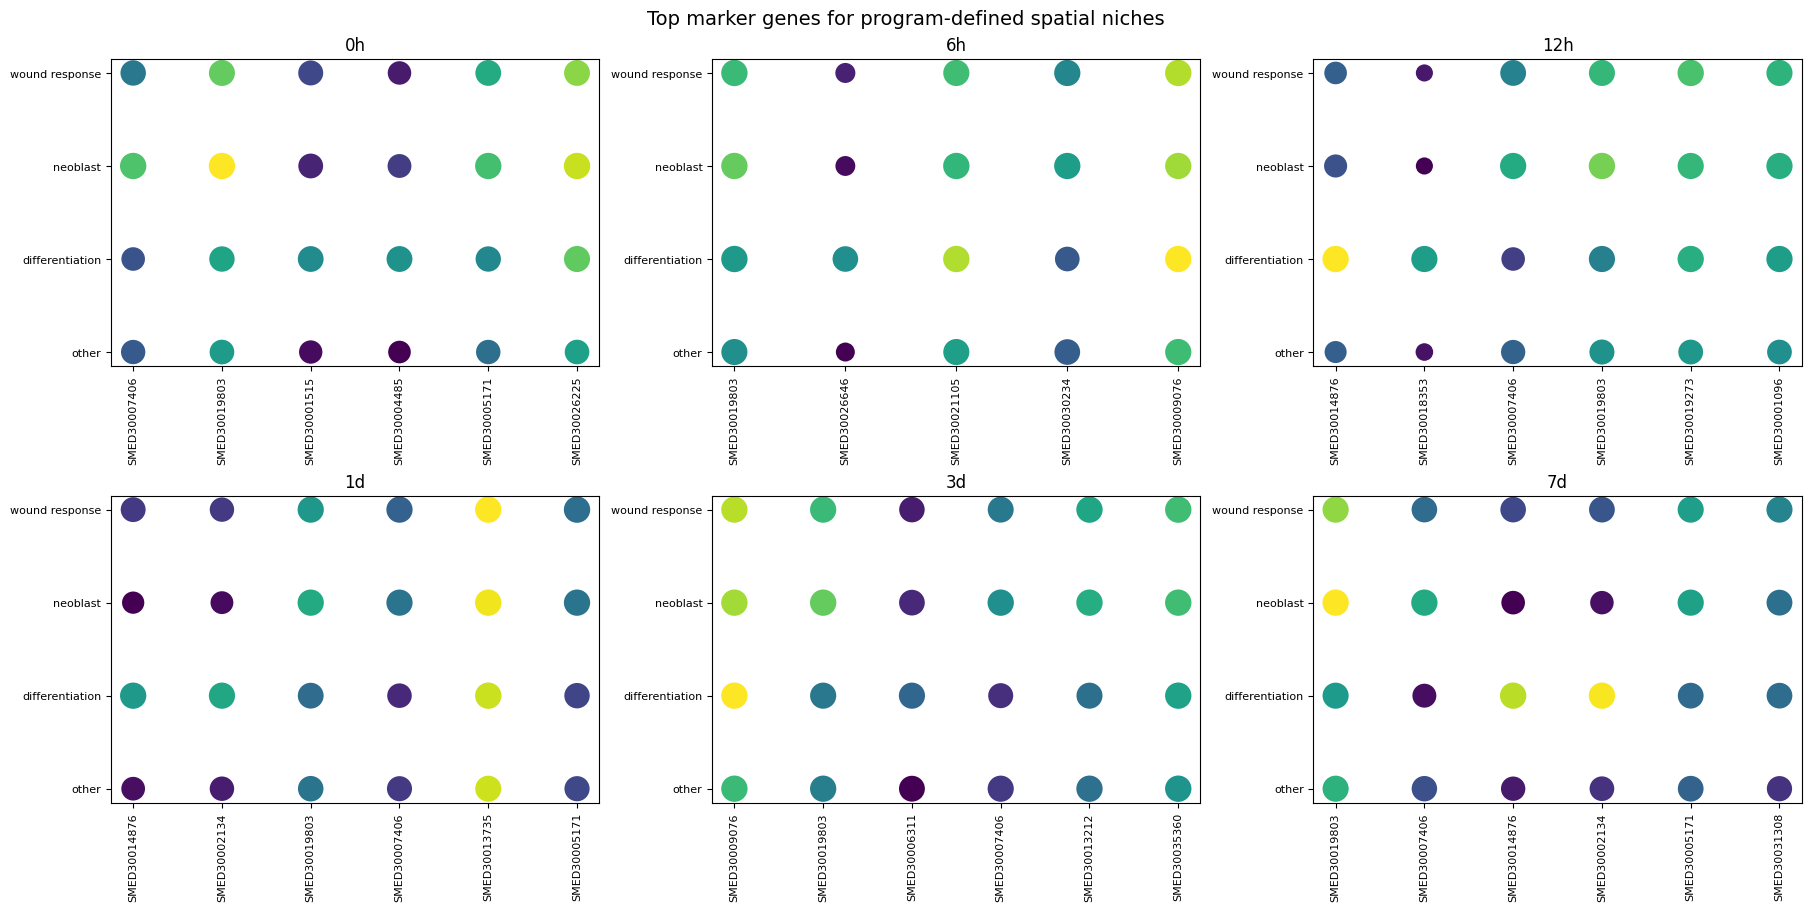

In [23]:
q4_dot_records = []

for timepoint, adata in visiums.items():
    top_genes = (
        q4_marker_table[q4_marker_table["timepoint"] == timepoint]
        .sort_values("scores", ascending=False)
        .groupby("program_group", observed=True)
        .head(2)["gene"]
        .drop_duplicates()
        .tolist()
    )

    for group in program_group_order:
        mask = adata.obs["program_group"].astype(str) == group
        if mask.sum() == 0:
            continue
        for gene in top_genes:
            values = adata[:, gene].X
            if hasattr(values, "toarray"):
                values = values.toarray()
            values = values.ravel()
            expressed = values > 0
            q4_dot_records.append({
                "timepoint": timepoint,
                "program_group": group,
                "gene": gene,
                "mean_expression": values[mask].mean(),
                "fraction_expressing": expressed[mask].mean(),
            })

q4_dot_df = pd.DataFrame(q4_dot_records)

fig, axes = plt.subplots(2, 3, figsize=(18, 9), constrained_layout=True)
axes = axes.flatten()

for ax, timepoint in zip(axes, timepoint_files.keys()):
    dot = q4_dot_df[q4_dot_df["timepoint"] == timepoint].copy()
    genes = dot["gene"].drop_duplicates().tolist()
    groups = program_group_order

    x_lookup = {gene: i for i, gene in enumerate(genes)}
    y_lookup = {group: i for i, group in enumerate(groups)}

    ax.scatter(
        dot["gene"].map(x_lookup),
        dot["program_group"].map(y_lookup),
        s=dot["fraction_expressing"] * 350 + 10,
        c=dot["mean_expression"],
        cmap="viridis",
        linewidths=0,
    )
    ax.set_title(timepoint)
    ax.set_xticks(range(len(genes)))
    ax.set_xticklabels(genes, rotation=90, fontsize=8)
    ax.set_yticks(range(len(groups)))
    ax.set_yticklabels([g.replace("high_", "").replace("_", " ") for g in groups], fontsize=8)
    ax.invert_yaxis()

fig.suptitle("Top marker genes for program-defined spatial niches", fontsize=14)
plt.show()


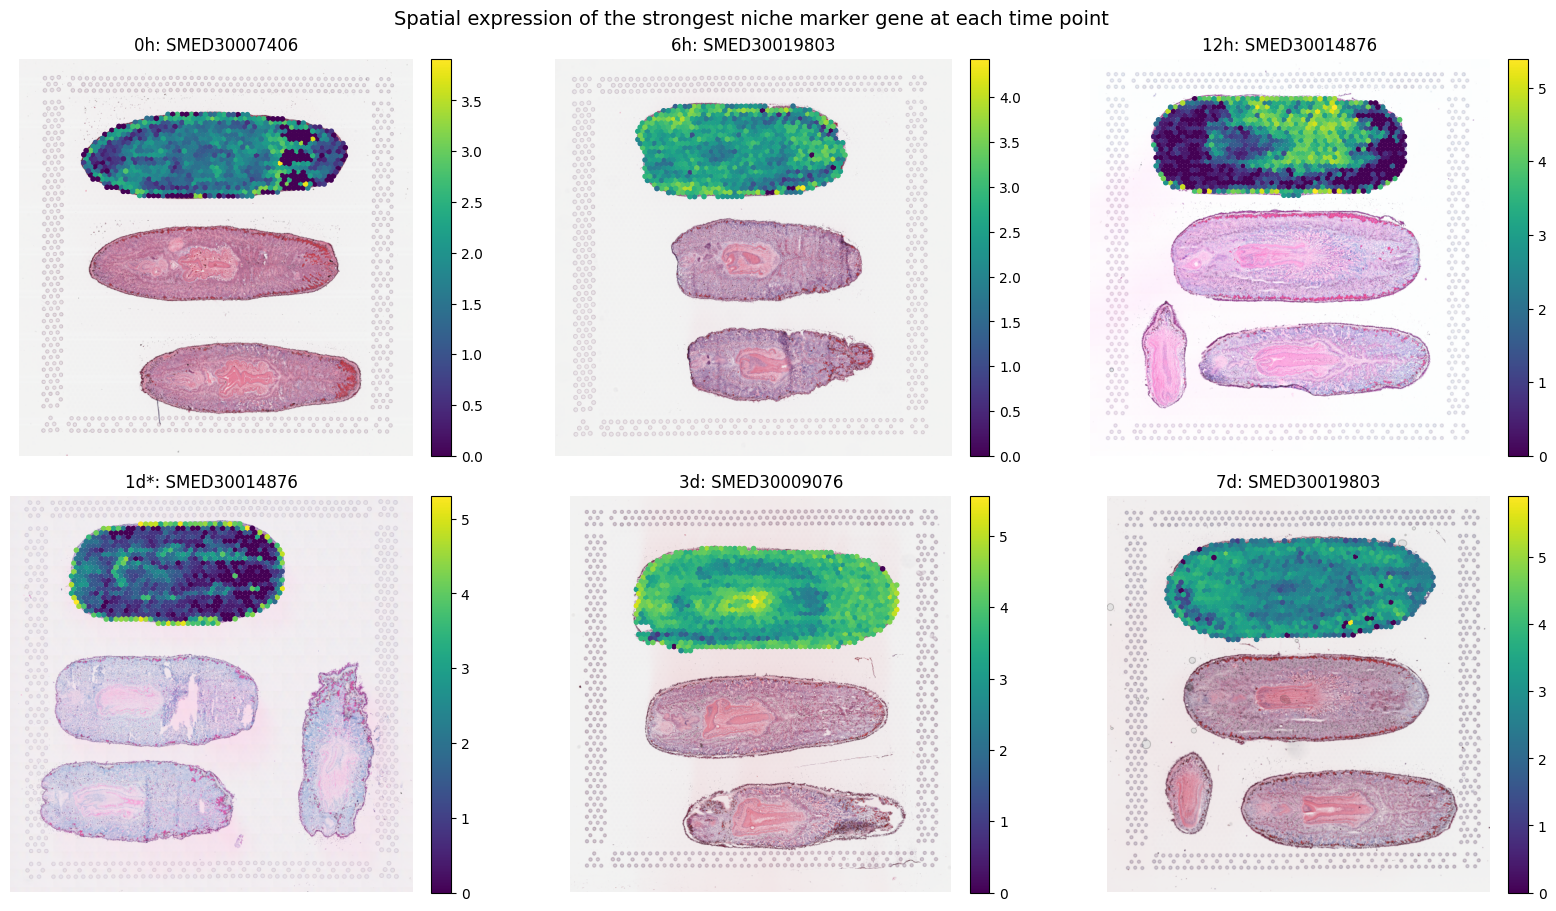

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9), constrained_layout=True)
axes = axes.flatten()

for ax, (timepoint, adata) in zip(axes, visiums.items()):
    top_gene = (
        q4_marker_table[q4_marker_table["timepoint"] == timepoint]
        .sort_values("scores", ascending=False)
        .iloc[0]["gene"]
    )

    img, coords = spatial_plot_inputs(adata, timepoint)
    values = adata[:, top_gene].X
    if hasattr(values, "toarray"):
        values = values.toarray()
    values = values.ravel()

    ax.imshow(img)
    points = ax.scatter(
        coords[:, 0],
        coords[:, 1],
        c=values,
        cmap="viridis",
        s=16,
        linewidths=0,
    )
    flip_label = "*" if timepoint in flipped_timepoints else ""
    ax.set_title(f"{timepoint}{flip_label}: {top_gene}")
    ax.set_xlim(0, img.shape[1])
    ax.set_ylim(img.shape[0], 0)
    ax.axis("off")
    fig.colorbar(points, ax=ax, fraction=0.046, pad=0.04)

fig.suptitle("Spatial expression of the strongest niche marker gene at each time point", fontsize=14)
plt.show()


This analysis identifies marker genes for the spatial niches defined in Q3. For each time point, each high-scoring program group is compared against the other spots using Wilcoxon differential expression. Genes with high scores and positive log fold changes are candidate markers enriched in the corresponding spatial niche.

The results show that the program-defined niches can be linked back to specific genes, but the marker patterns are not equally stable across programs. The high-neoblast niche has the most consistent marker signature across time, with genes such as SMED30007406, SMED30019803, and SMED30030234 recurring as top markers at multiple time points. The high-differentiation niche also has strong markers, especially around 12h, 1d, and 7d, with repeated genes such as SMED30014876, SMED30002134, and SMED30011419. In contrast, the high-wound-response niche is more time-specific, with top markers changing more across the regeneration time course. This matches the earlier result that wound-response activity and clustering were non-monotonic across time.

These genes should be interpreted as enriched candidate niche markers rather than exclusive markers. Some genes appear across multiple niches or time points. It means that the regenerative spatial domains share parts of their transcriptional programs instead of representing completely separate cell states.

### Question 5 (2 points)

Summarize what you have learned about how planarians regenerate.

In final project, I used Visium spatial transcriptomics to study how planarian regeneration is organized across both space and time. The main idea was to move from individual spatial genes to broader regenerative programs, then to spatial domains, and finally back to marker genes that define those domains.

What did I do through Q1-Q4:
Q1: I identified the genes with the strongest spatial organization at each regeneration time point using Moran's I. 
Q2: I grouped genes into wound-response, neoblast, and differentiation programs and showed that these programs change across both tissue space and regeneration time. 
Q3: I converted high program scores into spatial domains and showed that these high-scoring regions are spatially clustered, but not in a simple monotonic way over time. 
Q4: I identified candidate marker genes enriched in each program-defined spatial niche at each time point.

Together, these four analyses suggest that planarian regeneration is not just a global change in gene expression. Instead, regeneration-associated programs are spatially organized, and their organization changes across the time course. The neoblast program showed the most stable regenerative signal: it increased over time, remained spatially clustered, and had recurring marker genes such as SMED30007406, SMED30019803, and SMED30030234. Differentiation-associated regions also formed strong spatial domains, especially around 12h and later time points. Wound-response regions were more time-specific and non-monotonic, suggesting that wound-associated expression is reorganized over time rather than simply turning on early and fading away.

These conclusions are also consistent with the earlier analyses in our course. Our previous homework and lab analyses treated neoblasts as a key regeneration-associated population, and this project also found neoblast-associated programs to be central and spatially organized. The earlier hw6 analysis showed that neoblast abundance near amputated regions followed a transient, non-monotonic pattern rather than a simple linear increase; this matches the non-monotonic wound-response and spatial-clustering patterns observed here. The 1d section orientation issue identified in hw6 was also incorporated here by displaying the 1d spatial plots with a horizontal flip for cross-time comparison. Finally, the use of single-cell reference markers to define spatial programs follows the same logic as our previous pharynx-marker analysis, where reference-derived marker genes were projected onto Visium tissue space.